# Lab 09 — Gyro parameters (Option A: sin + rect)
Upload `lab9_gyro_240045.csv` to Colab and run all cells. Set `R_WHEEL` and `L_TRACK` from Lab 5.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
R_WHEEL, L_TRACK = 0.028, 0.160      # REPLACE with Lab 5 values (assumed here)
d = pd.read_csv('lab9_gyro_240045.csv')
d['t'] = (d.t_ms - d.t_ms.iloc[0])/1e3      # s (t_us is not real microseconds)
d['w'] = d.gz_mdps/1e3                       # deg/s
st = d[d.phase=='static']; ts = st.t.values-st.t.values[0]; ws = st.w.values
def cum(y,t): return np.concatenate([[0],np.cumsum(0.5*(y[1:]+y[:-1])*np.diff(t))])

## 1. Offset b0

b0 = 0.2854 deg/s (SE 0.0033), T = 30 s


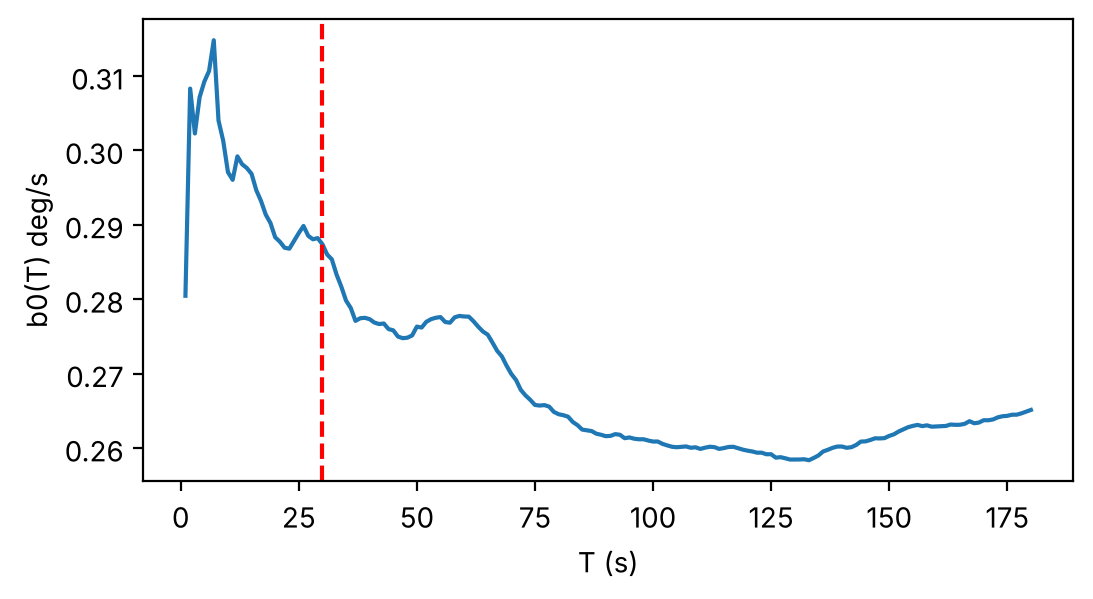

In [2]:
def calibrate_gyro(log, T=30, k=3):
    s=log[log.phase=='static']; t=(s.t_ms-s.t_ms.iloc[0])/1e3
    w=s.gz_mdps[t<=T].values/1e3; m=np.median(w); mad=1.4826*np.median(abs(w-m))
    return w[abs(w-m)<k*mad].mean()
b0=calibrate_gyro(d); se=ws[ts<=30].std(ddof=1)/np.sqrt((ts<=30).sum())
print(f'b0 = {b0:.4f} deg/s (SE {se:.4f}), T = 30 s')
Tg=np.arange(1,181); plt.figure(figsize=(6,3)); plt.plot(Tg,[ws[ts<=T].mean() for T in Tg]); plt.axvline(30,c='r',ls='--')
plt.xlabel('T (s)'); plt.ylabel('b0(T) deg/s'); plt.show()

## 2. Bias drift

In [3]:
wm=[ws[(ts>=a)&(ts<a+30)].mean() for a in range(0,180,30)]
d_rate=np.polyfit(np.arange(6)*30+15,wm,1)[0]*60
raw=cum(ws,ts); cor=cum(ws-b0,ts)
print('window means:',np.round(wm,3)); print(f'd = {d_rate:+.4f} deg/s/min')
print(f'raw heading drift = {np.polyfit(ts,raw,1)[0]*60:.1f} deg/min (b0*60 = {ws.mean()*60:.1f})')
print('error after b0 removal at 1/2/3 min:',[round(np.interp(m,ts,cor),2) for m in (60,120,179.9)],'deg')

window means: [0.287 0.268 0.23  0.254 0.27  0.283]
d = +0.0002 deg/s/min
raw heading drift = 15.5 deg/min (b0*60 = 15.9)
error after b0 removal at 1/2/3 min: [np.float64(-0.46), np.float64(-3.07), np.float64(-3.6)] deg


## 3. Rotation run: gyro vs encoder, range, scale factor

final: gyro 11.9 deg, encoder 8.6 deg
max gz: +164.6 / -161.1 deg/s (no flat top -> not saturated, lower bound)
sign: corr(gz, enc rate) = 0.987 (positive = CCW)


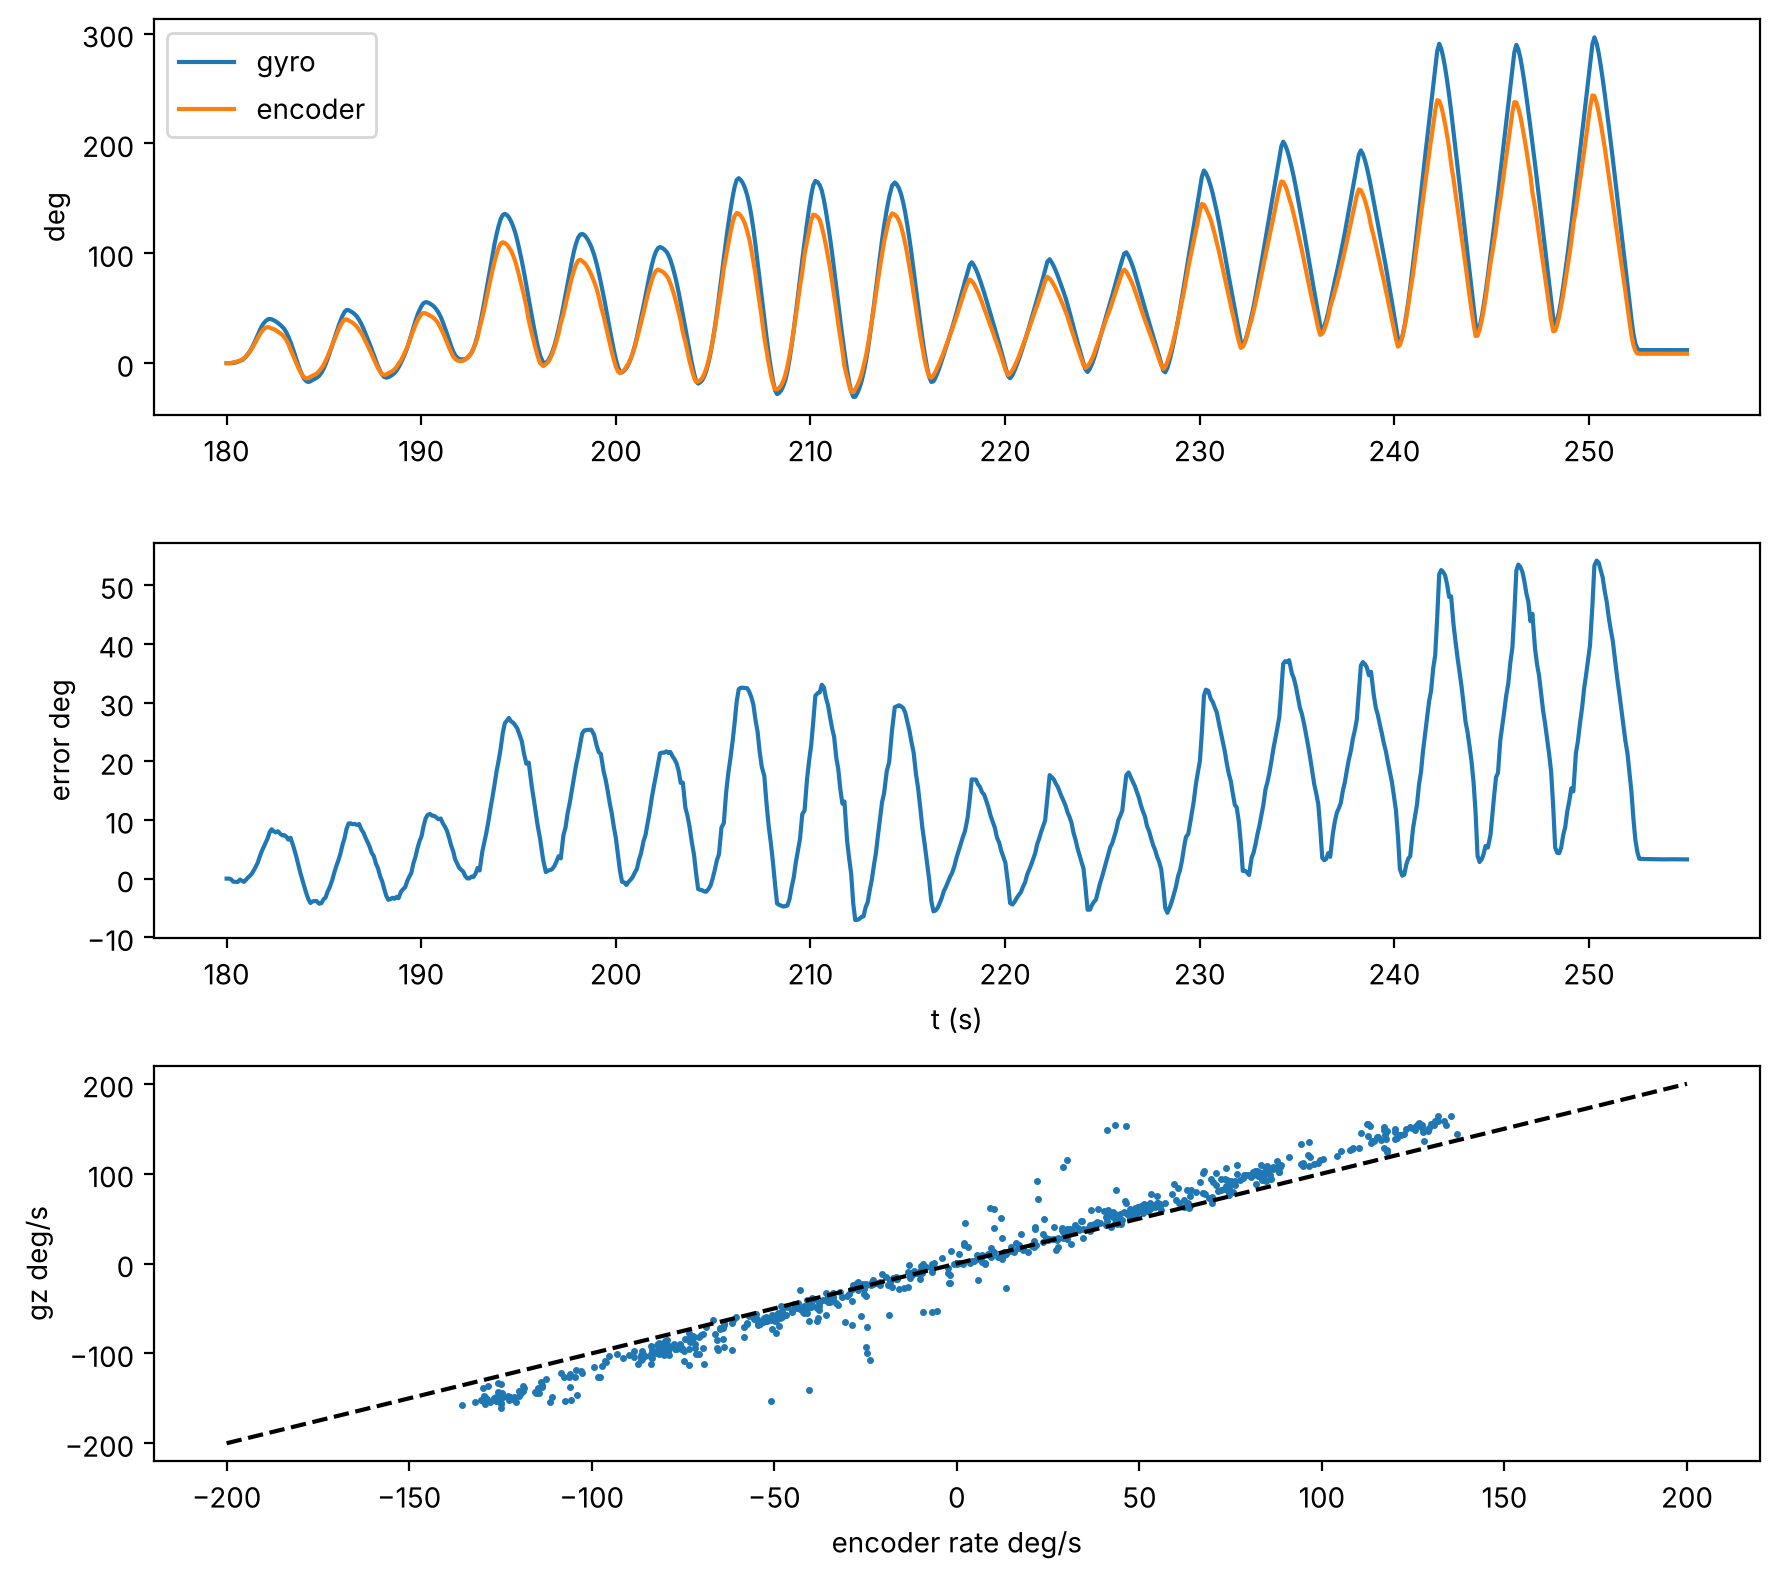

CCW: 1+s = 1.200 -> s = +20.0 %   | k_eff = 0.210 (assumed r/L = 0.175)
CW: 1+s = 1.204 -> s = +20.4 %   | k_eff = 0.211 (assumed r/L = 0.175)


In [4]:
r=d[d.phase!='static'].reset_index(drop=True); t=r.t.values
th_enc=(R_WHEEL/L_TRACK)*(r.encR-r.encL).values; th_enc-=th_enc[0]
th_gyro=cum(r.w.values-b0,t); w_enc=np.gradient(th_enc,t)
print(f'final: gyro {th_gyro[-1]:.1f} deg, encoder {th_enc[-1]:.1f} deg')
print(f'max gz: +{d.w.max():.1f} / {d.w.min():.1f} deg/s (no flat top -> not saturated, lower bound)')
print('sign: corr(gz, enc rate) =',round(np.corrcoef(r.w,w_enc)[0,1],3),'(positive = CCW)')
fig,ax=plt.subplots(3,1,figsize=(9,8))
ax[0].plot(t,th_gyro,label='gyro'); ax[0].plot(t,th_enc,label='encoder'); ax[0].legend(); ax[0].set_ylabel('deg')
ax[1].plot(t,th_gyro-th_enc); ax[1].set_ylabel('error deg'); ax[1].set_xlabel('t (s)')
ax[2].plot(w_enc,r.w,'.',ms=3); ax[2].plot([-200,200],[-200,200],'k--'); ax[2].set_xlabel('encoder rate deg/s'); ax[2].set_ylabel('gz deg/s')
plt.tight_layout(); plt.show()
# scale factor: gyro increment vs encoder increment per half-turn (split where encoder rate changes sign)
sg=np.sign(np.convolve(w_enc,np.ones(3)/3,'same')); sg[sg==0]=1; seg=np.cumsum(np.r_[0,sg[1:]!=sg[:-1]])
rows=[(sg[i[0]],th_gyro[i[-1]]-th_gyro[i[0]],th_enc[i[-1]]-th_enc[i[0]],((r.encR-r.encL).values[i[-1]]-(r.encR-r.encL).values[i[0]])) for i in (np.where(seg==s)[0] for s in np.unique(seg)) if len(i)>2]
S=pd.DataFrame(rows,columns=['sign','dg','de','dphi']); S=S[S.de.abs()>5]
for name,sgn in (('CCW',1),('CW',-1)):
    g=S[S['sign']==sgn]; sl=(g.dg*g.de).sum()/(g.de**2).sum(); k=(g.dg*g.dphi).sum()/(g.dphi**2).sum()
    print(f'{name}: 1+s = {sl:.3f} -> s = {(sl-1)*100:+.1f} %   | k_eff = {k:.3f} (assumed r/L = {R_WHEEL/L_TRACK:.3f})')

## 4. Resolution and noise

smallest step 8 mdeg/s; steps alternate 8/9 -> Delta = 8.75 mdeg/s = 0.00875 deg/s
sigma = 0.0717 deg/s, R = 0.00515, normality p = 0.56


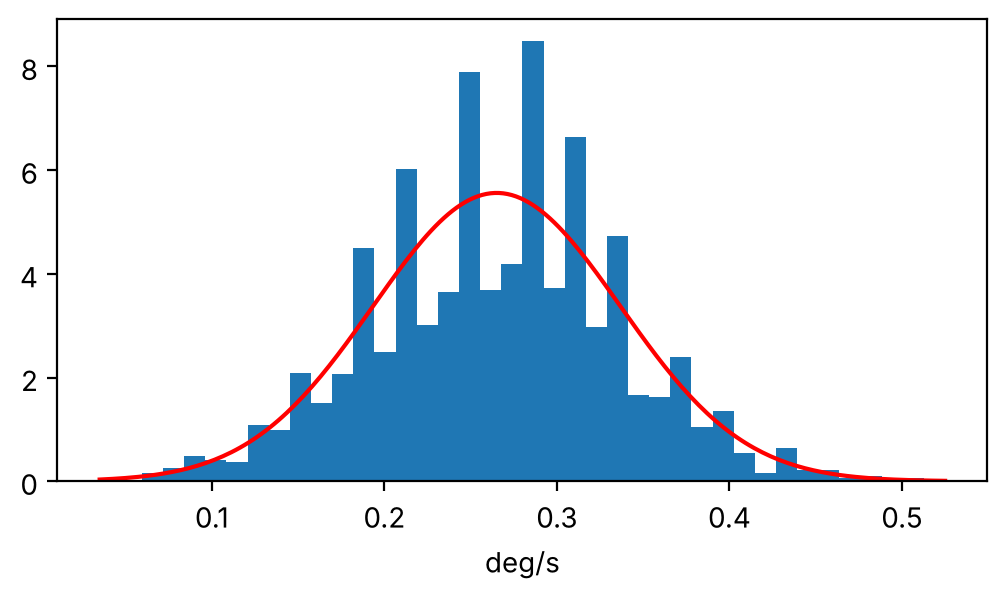

In [5]:
u=np.unique(st.gz_mdps); print('smallest step',np.diff(u).min(),'mdeg/s; steps alternate 8/9 -> Delta = 8.75 mdeg/s = 0.00875 deg/s')
sig=ws.std(ddof=1); print(f'sigma = {sig:.4f} deg/s, R = {sig**2:.5f}, normality p = {stats.normaltest(ws).pvalue:.2f}')
plt.figure(figsize=(6,3)); plt.hist(ws,40,density=True); g=np.linspace(ws.min(),ws.max(),200); plt.plot(g,stats.norm.pdf(g,ws.mean(),sig),'r'); plt.xlabel('deg/s'); plt.show()

## 5. Simulated gyro

RMSE sim vs real: 14.1 deg/s


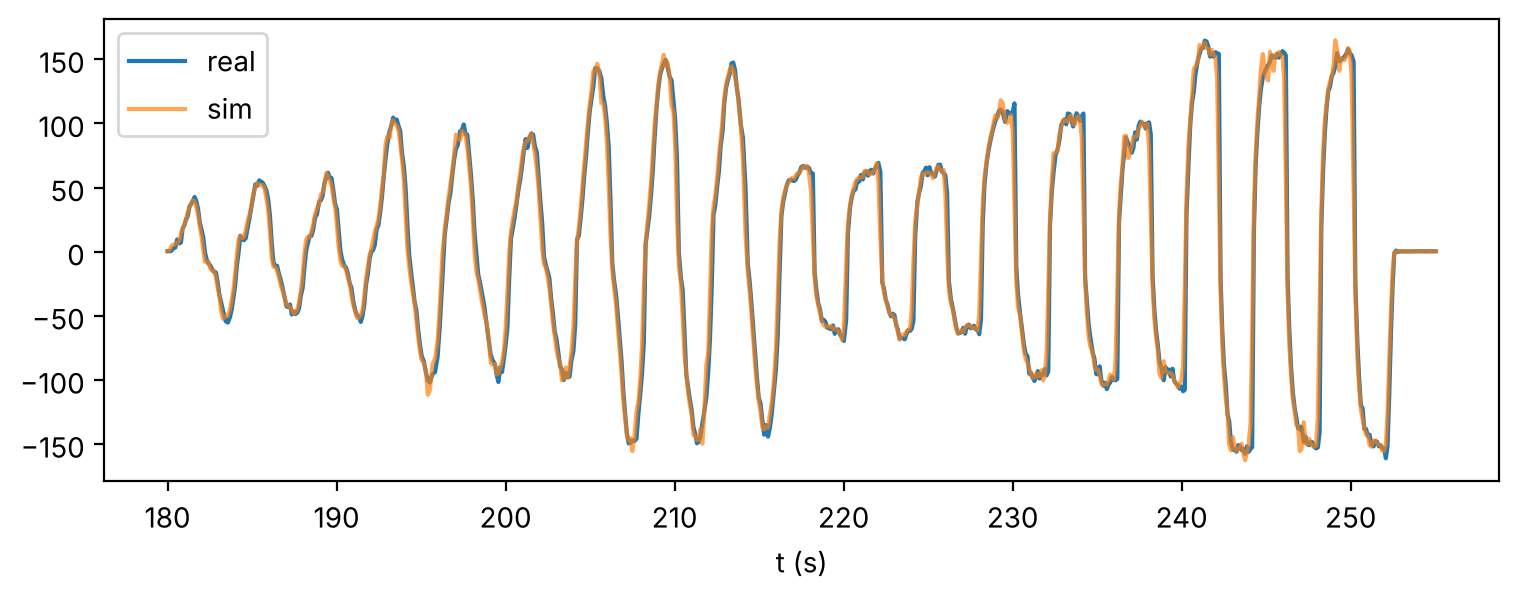

In [6]:
s_all=(S.dg*S.de).sum()/(S.de**2).sum()-1
P=dict(b0=b0,d=d_rate/60,wmax=245.0,delta=0.00875,sigma=sig,s=s_all)   # wmax assumed (not measured)
def gyro_sim(omega_true,t,p=P,seed=0):
    x=(1+p['s'])*omega_true+p['b0']+p['d']*t+np.random.default_rng(seed).normal(0,p['sigma'],len(t))
    return np.round(np.clip(x,-p['wmax'],p['wmax'])/p['delta'])*p['delta']
sim=gyro_sim(w_enc,t); print('RMSE sim vs real: %.1f deg/s'%np.sqrt(np.mean((sim-r.w)**2)))
plt.figure(figsize=(9,3)); plt.plot(t,r.w,label='real'); plt.plot(t,sim,alpha=.7,label='sim'); plt.legend(); plt.xlabel('t (s)'); plt.show()